Tujuan dari paper ini adalah untuk menganalisis data diabetes global dari tahun 2022-1990 yang bersumber oleh WHO. Hal yang dianalisa adalah min, max, mean, median, modus, standar devisasi, serta visualisasi data berupa grafik pada file csv

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import scipy
import folium

# Membaca data:
path1 = "/content/drive/MyDrive/Colab Notebooks/datasets2/825240004_DataBersih.xlsx"
dwd = pd.read_excel(path1)

# Strip whitespace from column names
dwd.columns = dwd.columns.str.strip()

A. Menampilkan isi file CSV

In [2]:
# Cetak 11 baris pertama dari kumpulan data
dwd.head(11)

,indicator,region,country,year,sex,age_group,prevalance,ci_low,ci_high
0,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_BTSX,30+ years of age,21.65,11.37,33.98
1,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_BTSX,18+ years,18.36,9.37,29.56
2,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_MLE,30+ years of age,22.24,8.80,40.60
3,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_MLE,18+ years,19.07,7.24,36.08
4,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_FMLE,30+ years of age,21.15,7.89,40.30
5,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2022,SEX_FMLE,18+ years,17.73,6.27,35.04
6,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2021,SEX_BTSX,30+ years of age,21.29,11.74,32.68
7,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2021,SEX_BTSX,18+ years,17.99,9.61,28.25
8,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2021,SEX_MLE,30+ years of age,21.90,9.24,38.85
9,NCD_DIABETES_PREVALENCE_AGESTD,AFR,Angola,2021,SEX_MLE,18+ years,18.71,7.73,34.14


In [3]:
#Cetak 6 baris terakhir dari kumpulan data
dwd.iloc[-6:]

,indicator,region,country,year,sex,age_group,prevalance,ci_low,ci_high
78798,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_BTSX,30+ years of age,15.01,11.52,18.85
78799,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_BTSX,18+ years,8.97,6.80,11.45
78800,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_MLE,30+ years of age,13.98,9.30,19.48
78801,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_MLE,18+ years,8.21,5.36,11.67
78802,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_FMLE,30+ years of age,16.04,11.17,21.72
78803,NCD_DIABETES_PREVALENCE_CRUDE,WPR,Samoa,1990,SEX_FMLE,18+ years,9.80,6.71,13.46


In [4]:
#Dapatkan info tentang variable data
dwd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78804 entries, 0 to 78803
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   indicator   78804 non-null  object 
 1   region      78804 non-null  object 
 2   country     78804 non-null  object 
 3   year        78804 non-null  int64  
 4   sex         78804 non-null  object 
 5   age_group   78804 non-null  object 
 6   prevalance  78804 non-null  float64
 7   ci_low      78804 non-null  float64
 8   ci_high     78804 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 5.4+ MB


In [5]:
dwd.columns

Index(['indicator', 'region', 'country', 'year', 'sex', 'age_group',
       'prevalance', 'ci_low', 'ci_high'],
      dtype='object')

In [6]:
duplicated = dwd.duplicated().sum()
print("There are %d duplicated records" % (duplicated))

There are 0 duplicated records


In [7]:
# Eksplorasi kumpulan data dan coba pahami arti dari setiap variabel (kolom).
# Identifikasi variabel mana yang kategoris dan mana yang numerik.

# - indicator : Jenis indikator prevalensi diabetes
#               (NCD_DIABETES_PREVALENCE_AGESTD = prevalensi terstandarisasi usia;
#                NCD_DIABETES_PREVALENCE_CRUDE  = prevalensi mentah/kasar)
#               → Kategorikal - nominal

# - region    : Wilayah, kawasan, atau daerah

# - country   : Negara

# - year      : Tahun pengukuran data (1990 hingga 2022)
#               → Numerik - diskrit (ordinal)

# - sex       : Jenis kelamin populasi yang diukur
#               (SEX_BTSX = kedua jenis kelamin;
#                SEX_MLE  = laki-laki;
#                SEX_FMLE = perempuan)
#               → Kategorikal - nominal

# - age_group : Kelompok usia populasi yang diukur
#               (30+ years of age = usia 30 tahun ke atas;
#                18+ years        = usia 18 tahun ke atas)
#               → Kategorikal - ordinal

# - prevalence: Persentase populasi yang menderita diabetes(%)
#               Nilai estimasi utama/titik tengah
#               → Numerik - kontinu

# - ci_low    : Batas bawah confidence interval 95% dari prevalensi(%)
#               Menunjukkan ketidakpastian pengukuran batas minimum
#               → Numerik - kontinu

# - ci_high   : Batas atas confidence interval 95% dari prevalensi(%)
#               Menunjukkan ketidakpastian pengukuran batas maksimum
#               → Numerik - kontinu

B. Perhitungan Min, Max, Mean, Median, Modus, Standar Devisasi

In [8]:
# ── Statistik Deskriptif dari file Excel baru ─────────────────────────
print("=" * 60)
print("STATISTIK DESKRIPTIF - DATA PREVALENSI DIABETES")
print("=" * 60)

col = "prevalance"   # sesuaikan dengan nama kolom pada file baru

# ── 1. Overall (semua data) ───────────────────────────────────────────
print("\nKESELURUHAN DATA:")
print("   Min    : {:.2f}%".format(dwd[col].min()))
print("   Max    : {:.2f}%".format(dwd[col].max()))
print("   Mean   : {:.2f}%".format(dwd[col].mean()))
print("   Median : {:.2f}%".format(dwd[col].median()))

mode_all = dwd[col].mode()
if len(mode_all) > 0:
    print("   Modus  : " + ", ".join(["{:.2f}%".format(x) for x in mode_all.tolist()]))
else:
    print("   Modus  : Tidak ada")

print("   Std Dev: {:.2f}%".format(dwd[col].std()))
print("   Range  : {:.2f}%".format(dwd[col].max() - dwd[col].min()))


STATISTIK DESKRIPTIF - DATA PREVALENSI DIABETES

KESELURUHAN DATA:
   Min    : 1.79%
   Max    : 46.98%
   Mean   : 12.04%
   Median : 9.95%
   Modus  : 6.57%
   Std Dev: 6.98%
   Range  : 45.19%


In [9]:
# ── 2. Per Indicator ──────────────────────────────────────────────────
print("\nPER INDICATOR:")
print(
    dwd.groupby("indicator")[col]
    .agg(
        Min="min",
        Max="max",
        Mean="mean",
        Median="median",
        Modus=lambda x: x.mode().iloc[0] if not x.mode().empty else None,
        Std_Dev="std"
    )
    .round(2)
    .to_string()
)


PER INDICATOR:
                                 Min    Max   Mean  Median  Modus  Std_Dev
indicator                                                                 
NCD_DIABETES_PREVALENCE_AGESTD  1.79  46.98  12.38   10.12   7.00     7.24
NCD_DIABETES_PREVALENCE_CRUDE   2.38  45.24  11.69    9.80   8.22     6.70


In [10]:
# ── 3. Per Sex ────────────────────────────────────────────────────────
print("\nPER JENIS KELAMIN:")
print(
    dwd.groupby("sex")[col]
    .agg(
        Min="min",
        Max="max",
        Mean="mean",
        Median="median",
        Modus=lambda x: x.mode().iloc[0] if not x.mode().empty else None,
        Std_Dev="std"
    )
    .round(2)
    .to_string()
)


PER JENIS KELAMIN:
           Min    Max   Mean  Median  Modus  Std_Dev
sex                                                 
SEX_BTSX  2.33  44.39  12.05    9.95   8.31     6.91
SEX_FMLE  1.79  46.98  12.41   10.10   7.00     7.35
SEX_MLE   2.38  45.24  11.65    9.80   5.75     6.65


In [11]:
# ── 4. Per Age Group ──────────────────────────────────────────────────
print("\nPER KELOMPOK USIA:")
print(
    dwd.groupby("age_group")[col]
    .agg(
        Min="min",
        Max="max",
        Mean="mean",
        Median="median",
        Modus=lambda x: x.mode().iloc[0] if not x.mode().empty else None,
        Std_Dev="std"
    )
    .round(2)
    .to_string()
)


PER KELOMPOK USIA:
                   Min    Max   Mean  Median  Modus  Std_Dev
age_group                                                   
18+  years        1.79  36.91  10.41    8.62   5.98     5.95
30+ years of age  2.35  46.98  13.66   11.34   9.78     7.54


In [12]:
# ── 5. Per Tahun (yearly summary) ─────────────────────────────────────
print("\nPER TAHUN:")
print(
    dwd.groupby("year")[col]
    .agg(
        Min="min",
        Max="max",
        Mean="mean",
        Median="median",
        Modus=lambda x: x.mode().iloc[0] if not x.mode().empty else None,
        Std_Dev="std"
    )
    .round(2)
    .to_string()
)


PER TAHUN:
       Min    Max   Mean  Median  Modus  Std_Dev
year                                            
1990  2.33  39.55   8.55    7.21   5.76     4.80
1991  2.38  39.68   8.75    7.33   4.92     4.92
1992  2.42  39.78   8.95    7.47   6.00     5.05
1993  2.45  39.86   9.16    7.65   6.53     5.18
1994  2.47  39.90   9.37    7.80   5.11     5.32
1995  2.49  39.90   9.58    7.98   5.90     5.46
1996  2.49  40.36   9.80    8.17   5.10     5.60
1997  2.47  41.38  10.01    8.35   5.16     5.75
1998  2.45  42.35  10.23    8.51   4.73     5.89
1999  2.42  43.28  10.45    8.64   7.83     6.04
2000  2.39  44.13  10.66    8.80   8.80     6.18
2001  2.36  44.89  10.88    8.97   5.94     6.32
2002  2.33  45.53  11.10    9.14   9.14     6.46
2003  2.30  46.05  11.32    9.32   6.64     6.58
2004  2.28  46.46  11.54    9.50   6.44     6.70
2005  2.25  46.74  11.77    9.68   6.60     6.81
2006  2.23  46.91  11.99    9.90   9.02     6.92
2007  2.20  46.98  12.21   10.09   6.12     7.00
2008  2.

C. Grafik

In [13]:
dwd["indicator"] = dwd["indicator"].map({
    "NCD_DIABETES_PREVALENCE_AGESTD": "Age-Standardized",
    "NCD_DIABETES_PREVALENCE_CRUDE": "Crude"
})

In [14]:
dwd = dwd.rename(columns={"prevalance": "prevalence"})

# Clean age_group text to avoid mismatch
dwd["age_group"] = dwd["age_group"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

# Rata-rata per tahun (semua grup digabung)
yearly_all = dwd.groupby("year")[["prevalence", "ci_low", "ci_high"]].mean().reset_index()

# Rata-rata per tahun per indicator
yearly_ind = dwd.groupby(["year", "indicator"])[["prevalence", "ci_low", "ci_high"]].mean().reset_index()
agestd = yearly_ind[yearly_ind["indicator"] == "Age-Standardized"].reset_index(drop=True)
crude = yearly_ind[yearly_ind["indicator"] == "Crude"].reset_index(drop=True)

# Rata-rata per tahun per age_group
yearly_age = dwd.groupby(["year", "age_group"])["prevalence"].mean().reset_index()
age30 = yearly_age[yearly_age["age_group"] == "30+ years of age"].reset_index(drop=True)
age18 = yearly_age[yearly_age["age_group"] == "18+ years"].reset_index(drop=True)

# Rata-rata prevalensi per age_group (overall)
avg_age = dwd.groupby("age_group")["prevalence"].mean().reset_index()

[GRAFIK 1] Line Chart: Tren Prevalensi Global per Tahun

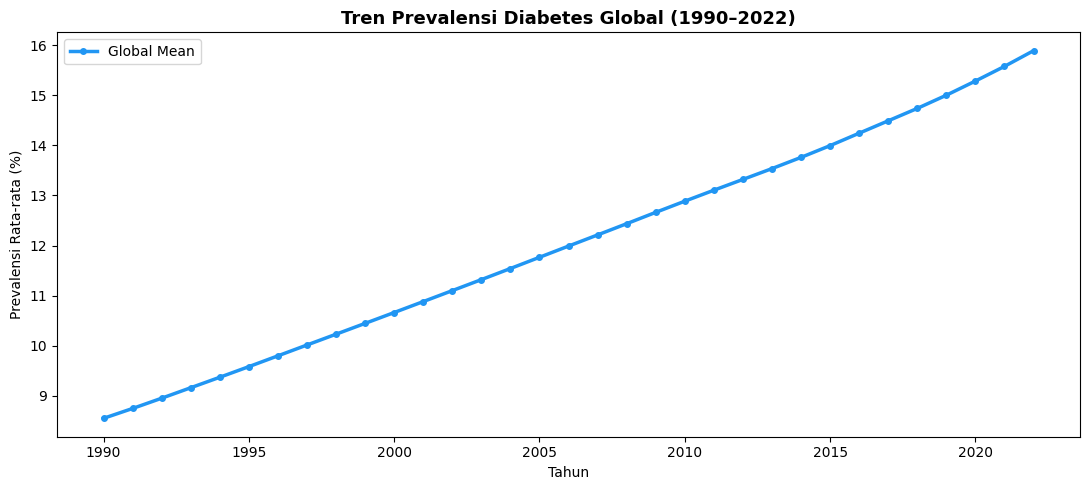

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    yearly_all["year"],
    yearly_all["prevalence"],
    color="#2196F3",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Global Mean"
)

ax.set_title("Tren Prevalensi Diabetes Global (1990–2022)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tahun")
ax.set_ylabel("Prevalensi Rata-rata (%)")
ax.legend()

plt.tight_layout()
plt.savefig("grafik1_tren_global.png", bbox_inches="tight")
plt.show()


[GRAFIK 2] — Line Chart: Age-Standardized vs Crude per *Tahun*

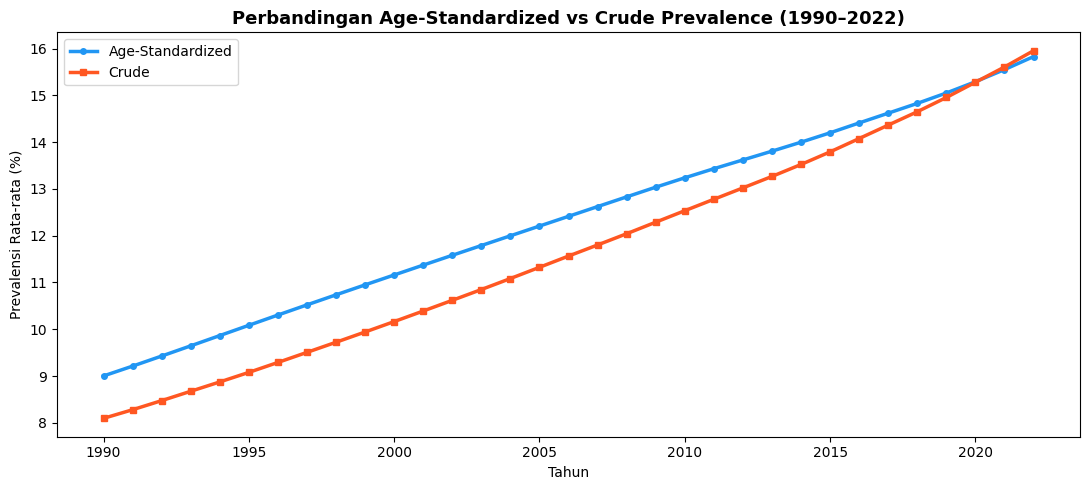

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    agestd["year"],
    agestd["prevalence"],
    color="#2196F3",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Age-Standardized"
)

ax.plot(
    crude["year"],
    crude["prevalence"],
    color="#FF5722",
    linewidth=2.5,
    marker="s",
    markersize=4,
    label="Crude"
)

ax.set_title("Perbandingan Age-Standardized vs Crude Prevalence (1990–2022)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tahun")
ax.set_ylabel("Prevalensi Rata-rata (%)")
ax.legend()

plt.tight_layout()
plt.savefig("grafik2_agestd_vs_crude.png", bbox_inches="tight")
plt.show()

[GRAFIK 3] — Bar Chart: Rata-rata Prevalensi 18+ vs 30+

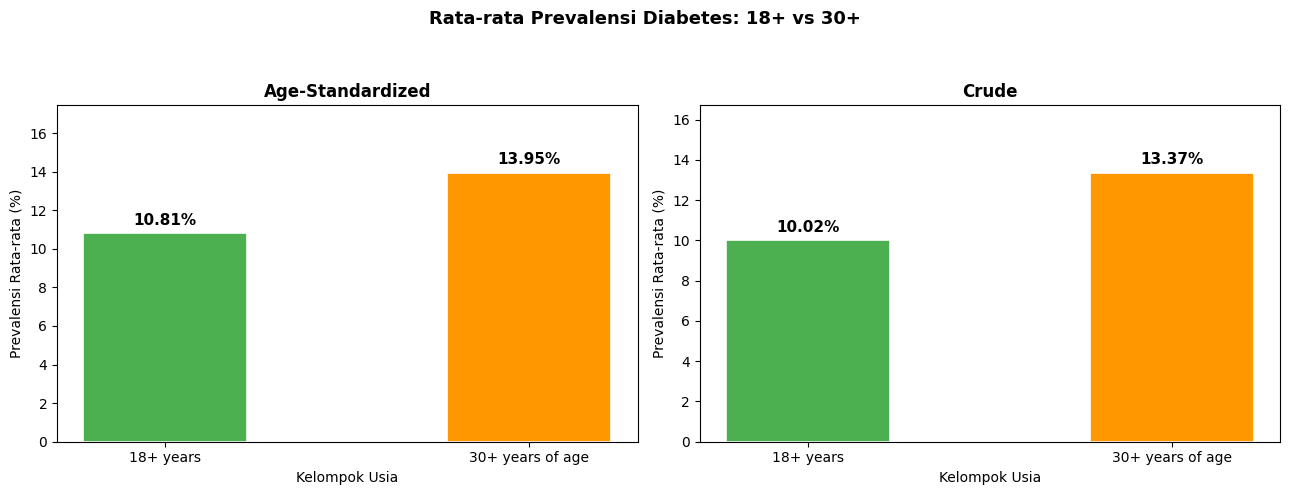

In [17]:
# GRAFIK 3 — Bar Chart: Rata-rata Prevalensi 18+ vs 30+
avg_age_ind = dwd.groupby(["indicator", "age_group"])["prevalence"].mean().reset_index()

agestd_age = avg_age_ind[avg_age_ind["indicator"] == "Age-Standardized"].reset_index(drop=True)
crude_age = avg_age_ind[avg_age_ind["indicator"] == "Crude"].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Rata-rata Prevalensi Diabetes: 18+ vs 30+", fontsize=13, fontweight="bold")

bars1 = axes[0].bar(agestd_age["age_group"], agestd_age["prevalence"],
                    color=["#4CAF50", "#FF9800"], width=0.45,
                    edgecolor="white", linewidth=1.2)
axes[0].bar_label(bars1, fmt="%.2f%%", padding=4, fontsize=11, fontweight="bold")
axes[0].set_title("Age-Standardized", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Kelompok Usia")
axes[0].set_ylabel("Prevalensi Rata-rata (%)")
axes[0].set_ylim(0, agestd_age["prevalence"].max() * 1.25)

bars2 = axes[1].bar(crude_age["age_group"], crude_age["prevalence"],
                    color=["#4CAF50", "#FF9800"], width=0.45,
                    edgecolor="white", linewidth=1.2)
axes[1].bar_label(bars2, fmt="%.2f%%", padding=4, fontsize=11, fontweight="bold")
axes[1].set_title("Crude", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kelompok Usia")
axes[1].set_ylabel("Prevalensi Rata-rata (%)")
axes[1].set_ylim(0, crude_age["prevalence"].max() * 1.25)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("grafik3_bar_agegroup_split.png", bbox_inches="tight")
plt.show()

[GRAFIK 4] — Horizontal Bar Chart: Top 10 Countries in the Latest Year

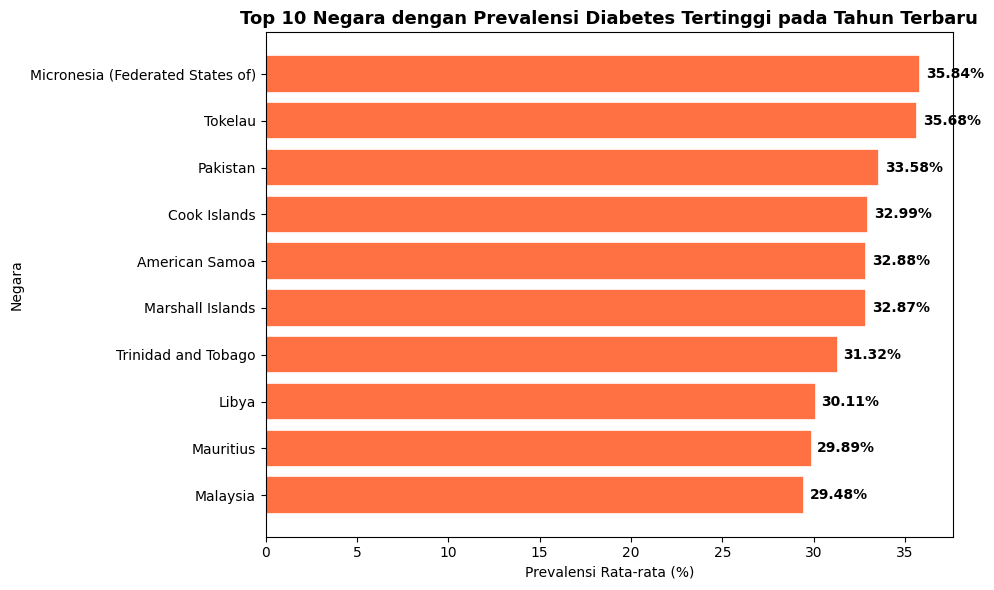

In [18]:
latest_year = dwd["year"].max()

latest_data = dwd[dwd["year"] == latest_year]

top10_countries = (
    latest_data.groupby("country")["prevalence"]
    .mean()
    .reset_index()
    .sort_values("prevalence", ascending=False)
    .head(10)
    .sort_values("prevalence", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10_countries["country"],
    top10_countries["prevalence"],
    color="#FF7043",
    edgecolor="white",
    linewidth=1.2
)

ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=10, fontweight="bold")
ax.set_title("Top 10 Negara dengan Prevalensi Diabetes Tertinggi pada Tahun Terbaru", fontsize=13, fontweight="bold")
ax.set_xlabel("Prevalensi Rata-rata (%)")
ax.set_ylabel("Negara")

plt.tight_layout()
plt.savefig("grafik4_top10_countries_latest_year.png", bbox_inches="tight")
plt.show()

[GRAFIK 5] — Bar Chart: Average Diabetes Prevalence by Region

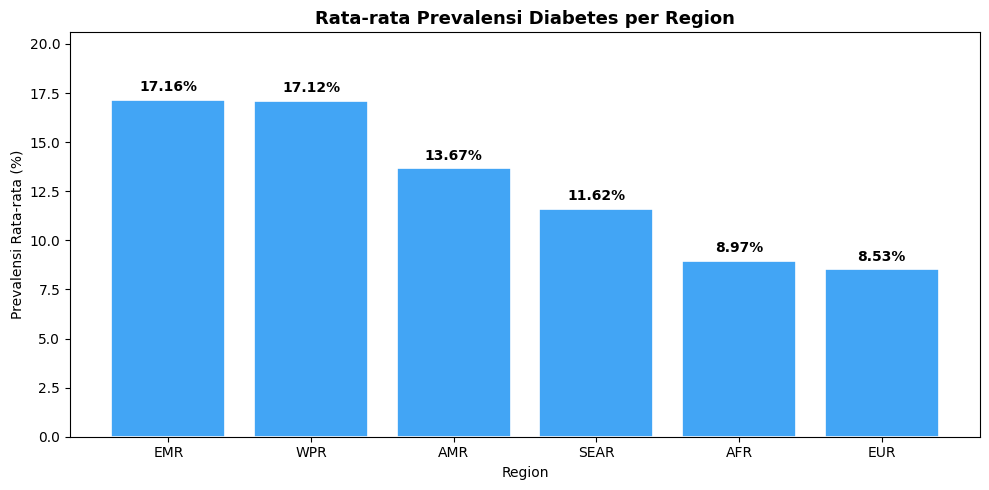

In [19]:
avg_region = (
    dwd.groupby("region")["prevalence"]
    .mean()
    .reset_index()
    .sort_values("prevalence", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    avg_region["region"],
    avg_region["prevalence"],
    color="#42A5F5",
    edgecolor="white",
    linewidth=1.2
)

ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=10, fontweight="bold")
ax.set_title("Rata-rata Prevalensi Diabetes per Region", fontsize=13, fontweight="bold")
ax.set_xlabel("Region")
ax.set_ylabel("Prevalensi Rata-rata (%)")
ax.set_ylim(0, avg_region["prevalence"].max() * 1.20)

plt.tight_layout()
plt.savefig("grafik5_avg_prevalence_region.png", bbox_inches="tight")
plt.show()

In [20]:
!jupyter nbconvert '/content/UAS_BigData.ipynb' --to html

[NbConvertApp] WARNING | pattern '/content/UAS_BigData.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--ex